<a href="https://colab.research.google.com/github/wajd-ops/Coffee-Purchase-Prediction/blob/main/Coffee-Purchase-Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import pandas as pd

PROJECT_NAME = "Coffee Purchase Prediction"
TARGET_COLUMN = "Bought_Coffee"

data = {
"Cups_Per_Week":[22,15,20,3,10,7,17,1],
"Visits":[13,8,10,3,6,7,11,1],
"Avg_Spend":[100,68,89,25,50,45,7,15],
"Bought_Coffee":[1,1,1,0,0,0,1,0],
}

df = pd.DataFrame(data)

print("📌 Project:", PROJECT_NAME)
print("\n📋 First Records:\n", df.head())
print("\n📊 Dataset Shape:", df.shape)
print("\n🔍 Missing Values:\n", df.isnull().sum())
print("\n🎯 Target Distribution:\n", df[TARGET_COLUMN].value_counts())

📌 Project: Coffee Purchase Prediction

📋 First Records:
    Cups_Per_Week  Visits  Avg_Spend  Bought_Coffee
0             22      13        100              1
1             15       8         68              1
2             20      10         89              1
3              3       3         25              0
4             10       6         50              0

📊 Dataset Shape: (8, 4)

🔍 Missing Values:
 Cups_Per_Week    0
Visits           0
Avg_Spend        0
Bought_Coffee    0
dtype: int64

🎯 Target Distribution:
 Bought_Coffee
1    4
0    4
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
X, y,
test_size=0.25,
random_state=10,
stratify=y
)

print("📘 Training Records:", len(X_train))
print("📗 Testing Records:", len(X_test))
print("✅ Data split successfully!")


📘 Training Records: 6
📗 Testing Records: 2
✅ Data split successfully!


In [23]:
COLUMN_1 = "Cups_Per_Week"
COLUMN_2 = "Visits"
NEW_FEATURE = "Cups_Per_Visit"

X_train = X_train.copy()
X_test = X_test.copy()

for dataset in [X_train, X_test]:
    dataset[NEW_FEATURE] = dataset[COLUMN_1] / (dataset[COLUMN_2] + 1)

print("🛠️ New Feature Created:", NEW_FEATURE)
print("\n📋 Updated Training Data:\n", X_train.head())
print("\n📊 Total Features:", X_train.shape[1])


🛠️ New Feature Created: Cups_Per_Visit

📋 Updated Training Data:
    Cups_Per_Week  Visits  Avg_Spend  Cups_Per_Visit
7              1       1         15        0.500000
5              7       7         45        0.875000
0             22      13        100        1.571429
3              3       3         25        0.750000
1             15       8         68        1.666667

📊 Total Features: 4


In [24]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

prep = make_column_transformer(
(make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
make_column_selector(dtype_include="number")),
(make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")),
make_column_selector(dtype_include="object"))
)

model_lr = make_pipeline(prep, LogisticRegression(max_iter=1000))
model_rf = make_pipeline(prep, RandomForestClassifier(random_state=10))

model_lr.fit(X_train, y_train)
model_rf.fit(X_train, y_train)

print("✅ Pipeline & Logistic Regression trained!")
print("✅ Pipeline & Random Forest trained!")


✅ Pipeline & Logistic Regression trained!
✅ Pipeline & Random Forest trained!


In [25]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

gb_pipeline = make_pipeline(prep, GradientBoostingClassifier(random_state=10))

params = {
"gradientboostingclassifier__n_estimators":[20,50],
"gradientboostingclassifier__learning_rate": [0.05, 0.1],
"gradientboostingclassifier__max_depth":[1,2]
}

search = GridSearchCV(gb_pipeline, params, scoring="average_precision", cv=2)
search.fit(X_train, y_train)
best_model = search.best_estimator_

print("🔧 Best Parameters:", search.best_params_)
print("📊 Best CV PR-AUC:", round(search.best_score_, 2))



🔧 Best Parameters: {'gradientboostingclassifier__learning_rate': 0.05, 'gradientboostingclassifier__max_depth': 1, 'gradientboostingclassifier__n_estimators': 20}
📊 Best CV PR-AUC: 1.0


In [26]:
from sklearn.metrics import accuracy_score, f1_score, average_precision_score, confusion_matrix

probabilities = best_model.predict_proba(X_test)[:, 1]
threshold = 0.5
predictions = (probabilities >= threshold).astype(int)

print("🎯 Threshold:", threshold)
print("🎯 Accuracy:", round(accuracy_score(y_test, predictions), 2))
print("📊 PR-AUC:", round(average_precision_score(y_test, probabilities), 2))
print("📈 F1 Score:", round(f1_score(y_test, predictions, zero_division=0), 2))
print("🔍 Confusion Matrix:\n", confusion_matrix(y_test, predictions))

# استخراج أهمية الخصائص من أفضل نموذج
feature_names = best_model.named_steps["columntransformer"].get_feature_names_out()
importances = best_model.named_steps["gradientboostingclassifier"].feature_importances_

importance_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print("\n📊 Feature Importance:")
print(importance_series.round(2))
print("🏆 Most Important Feature:", importance_series.index[0])



🎯 Threshold: 0.5
🎯 Accuracy: 1.0
📊 PR-AUC: 1.0
📈 F1 Score: 1.0
🔍 Confusion Matrix:
 [[1 0]
 [0 1]]

📊 Feature Importance:
pipeline-1__Cups_Per_Visit    0.36
pipeline-1__Visits            0.34
pipeline-1__Avg_Spend         0.16
pipeline-1__Cups_Per_Week     0.15
dtype: float64
🏆 Most Important Feature: pipeline-1__Cups_Per_Visit


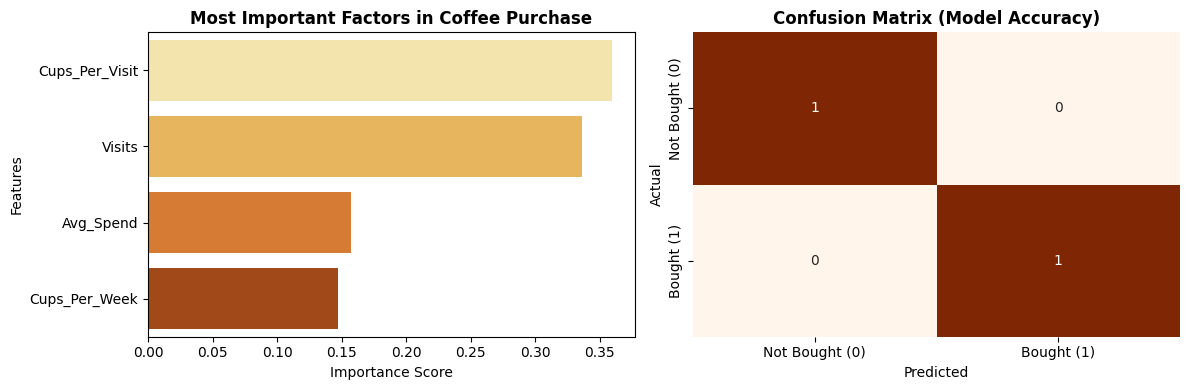

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# إعداد شكل وحجم الرسم البياني
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# الرسم الأول: أهمية العوامل المؤثرة في شراء القهوة
clean_names = [name.split("__")[-1] for name in importance_series.index]
sns.barplot(x=importance_series.values, y=clean_names,hue=clean_names, legend=False,ax=axes[0], palette="YlOrBr")
axes[0].set_title("Most Important Factors in Coffee Purchase", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Importance Score")
axes[0].set_ylabel("Features")

# الرسم الثاني: مصفوفة الارتباك (Confusion Matrix)
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False, ax=axes[1],
xticklabels=["Not Bought (0)", "Bought (1)"],
yticklabels=["Not Bought (0)", "Bought (1)"])
axes[1].set_title("Confusion Matrix (Model Accuracy)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()
